In [1]:

# Standard libraries
import os
from pathlib import Path
from collections import Counter

# Data manipulation
import numpy as np
import pandas as pd

# Image processing
import cv2
from PIL import Image

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Utilities
from tqdm.notebook import tqdm

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

PROJECT_ROOT = Path(r"C:\\cs\\Projects\\cv-projects\\Brain_tumor")

DATASET_DIR = PROJECT_ROOT / "data" / "raw"

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "data" / "reports"

CLASS_NAMES = [
    "normal",
    "glioma_tumor",
    "meningioma_tumor",
    "pituitary_tumor"
]

print("Dataset directory:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())

for class_name in CLASS_NAMES:
    class_path = DATASET_DIR / class_name
    print(f"{class_name}: {class_path.exists()}")


Dataset directory: C:\cs\Projects\cv-projects\Brain_tumor\data\raw
Dataset exists: True
normal: True
glioma_tumor: True
meningioma_tumor: True
pituitary_tumor: True


In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

image_records = []

for class_name in CLASS_NAMES:
    class_dir = DATASET_DIR / class_name

    for image_path in class_dir.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            image_records.append({
                "image_path": str(image_path),
                "filename": image_path.name,
                "class": class_name,
                "extension": image_path.suffix.lower()
            })

df = pd.DataFrame(image_records)

print(f"Total images: {len(df)}")
print(f"Total classes: {df['class'].nunique()}")

display(df.head())

Total images: 3096
Total classes: 4


,image_path,filename,class,extension
0,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,N_1.jpg,normal,.jpg
1,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,N_10.jpg,normal,.jpg
2,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,N_100.jpg,normal,.jpg
3,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,N_101.jpg,normal,.jpg
4,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,N_102.jpg,normal,.jpg


,image_count
class,
normal,438
glioma_tumor,901
meningioma_tumor,913
pituitary_tumor,844


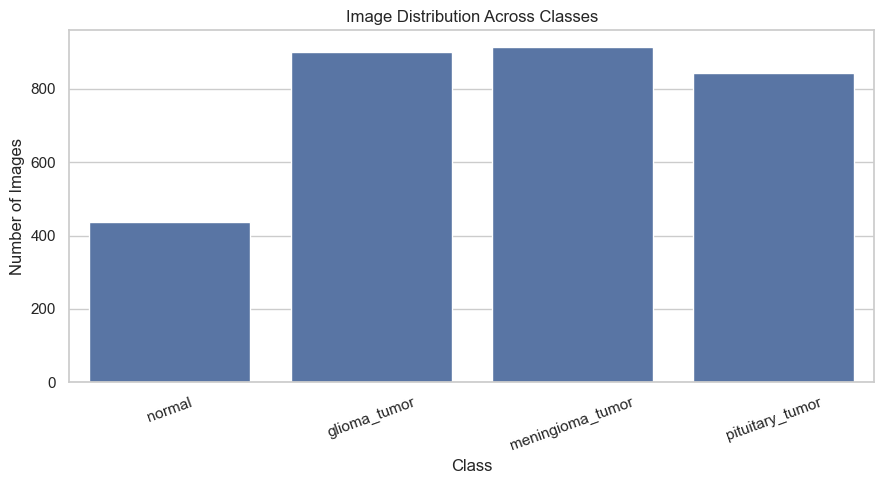

In [5]:
class_counts = (
    df["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

display(class_counts.to_frame("image_count"))

plt.figure(figsize=(9, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)

plt.title("Image Distribution Across Classes")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [6]:
image_properties = []

for image_path in tqdm(df["image_path"]):
    try:
        with Image.open(image_path) as img:
            image_properties.append({
                "image_path": image_path,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "format": img.format,
                "status": "valid"
            })

    except Exception:
        image_properties.append({
            "image_path": image_path,
            "width": None,
            "height": None,
            "mode": None,
            "format": None,
            "status": "corrupted"
        })

properties_df = pd.DataFrame(image_properties)

print("Image audit completed!")
print("Valid images:", (properties_df["status"] == "valid").sum())
print("Corrupted images:", (properties_df["status"] == "corrupted").sum())

  0%|          | 0/3096 [00:00<?, ?it/s]

Image audit completed!
Valid images: 3096
Corrupted images: 0


In [7]:
valid_df = properties_df[properties_df["status"] == "valid"]

print("Image dimensions:")
display(
    valid_df.groupby(["width", "height"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

print("\nImage modes:")
display(valid_df["mode"].value_counts())

print("\nImage formats:")
display(valid_df["format"].value_counts())

Image dimensions:


,width,height,count
0,256,256,3096



Image modes:


mode
RGB    3096
Name: count, dtype: int64


Image formats:


format
JPEG    3096
Name: count, dtype: int64

In [8]:
import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for image_path in tqdm(df["image_path"]):
    try:
        with Image.open(image_path) as img:
            img = img.convert("RGB")

            image_hash = hashlib.sha256(
                img.tobytes()
            ).hexdigest()

            hash_groups[image_hash].append(image_path)

    except Exception:
        continue

# Keep groups containing duplicates only
duplicate_groups = {
    image_hash: paths
    for image_hash, paths in hash_groups.items()
    if len(paths) > 1
}

print("Duplicate groups:", len(duplicate_groups))
print(
    "Duplicate images beyond the first:",
    sum(len(paths) - 1 for paths in duplicate_groups.values())
)

  0%|          | 0/3096 [00:00<?, ?it/s]

Duplicate groups: 217
Duplicate images beyond the first: 251


In [9]:
duplicate_records = []

for image_hash, paths in duplicate_groups.items():
    for path in paths:
        duplicate_records.append({
            "image_hash": image_hash,
            "image_path": path,
            "class": Path(path).parent.name
        })

duplicates_df = pd.DataFrame(duplicate_records)

display(duplicates_df)

,image_hash,image_path,class
0,d12d90037a95d94137979443dbd00eef79498a68fafb28...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal
1,d12d90037a95d94137979443dbd00eef79498a68fafb28...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal
2,d12d90037a95d94137979443dbd00eef79498a68fafb28...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal
3,cd0375e3709c77a28203f70b06bb4f438ad9b2ad0cda5b...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal
4,cd0375e3709c77a28203f70b06bb4f438ad9b2ad0cda5b...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal
...,...,...,...
463,c58fb61ae4c03eff17a8a8855265921cc5288f7e2175ee...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,pituitary_tumor
464,18c57ee0acf3c81a041997ddb44054507b4af87e1872ec...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,pituitary_tumor
465,18c57ee0acf3c81a041997ddb44054507b4af87e1872ec...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,pituitary_tumor
466,ef57c0501d82aa4e4b2019dfa4ba30f591abc1f64777b6...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,pituitary_tumor


In [10]:
cross_class_duplicates = (
    duplicates_df.groupby("image_hash")
    .agg(
        classes=("class", "nunique"),
        class_names=("class", lambda x: list(x.unique())),
        image_count=("image_path", "count")
    )
    .query("classes > 1")
)

print("Cross-class duplicate groups:", len(cross_class_duplicates))

display(cross_class_duplicates)

Cross-class duplicate groups: 0


,classes,class_names,image_count
image_hash,,,


In [11]:
pip install ImageHash==4.3.2

   ---------------------------------------- 0.0/4.2 MB ? eta -:--:--
   ---- ----------------------------------- 0.5/4.2 MB 2.4 MB/s eta 0:00:02
   --------- ------------------------------ 1.0/4.2 MB 2.5 MB/s eta 0:00:02
   ------------ --------------------------- 1.3/4.2 MB 2.3 MB/s eta 0:00:02
   ----------------- ---------------------- 1.8/4.2 MB 2.4 MB/s eta 0:00:01
   ------------------- -------------------- 2.1/4.2 MB 2.1 MB/s eta 0:00:02
   ------------------- -------------------- 2.1/4.2 MB 2.1 MB/s eta 0:00:02
   ---------------------- ----------------- 2.4/4.2 MB 1.7 MB/s eta 0:00:02
   ------------------------ --------------- 2.6/4.2 MB 1.6 MB/s eta 0:00:01
   ----------------------------- ---------- 3.1/4.2 MB 1.7 MB/s eta 0:00:01
   -------------------------------- ------- 3.4/4.2 MB 1.7 MB/s eta 0:00:01
   ------------------------------------- -- 3.9/4.2 MB 1.7 MB/s eta 0:00:01
   ---------------------------------------- 4.2/4.2 MB 1.7 MB/s  0:00:02

   ------------------

In [12]:
import imagehash
from itertools import combinations

image_hashes = {}

for image_path in tqdm(df["image_path"]):
    try:
        with Image.open(image_path) as img:
            image_hashes[image_path] = imagehash.phash(img.convert("RGB"))
    except Exception:
        continue

print("Images hashed:", len(image_hashes))

  0%|          | 0/3096 [00:00<?, ?it/s]

Images hashed: 3096


In [13]:
near_duplicates = []

image_paths = list(image_hashes.keys())

for path1, path2 in tqdm(combinations(image_paths, 2),
                         total=len(image_paths) * (len(image_paths) - 1) // 2):

    distance = image_hashes[path1] - image_hashes[path2]

    if 0 < distance <= 5:
        near_duplicates.append({
            "image_1": path1,
            "image_2": path2,
            "class_1": Path(path1).parent.name,
            "class_2": Path(path2).parent.name,
            "hash_distance": distance
        })

near_duplicates_df = pd.DataFrame(near_duplicates)

print("Near-duplicate pairs:", len(near_duplicates_df))
display(near_duplicates_df.head(20))

  0%|          | 0/4791060 [00:00<?, ?it/s]

Near-duplicate pairs: 317


,image_1,image_2,class_1,class_2,hash_distance
0,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal,normal,4
1,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal,normal,2
2,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal,normal,2
3,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal,normal,2
4,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal,normal,2
5,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal,normal,4
6,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal,normal,2
7,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal,normal,2
8,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal,normal,2
9,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,normal,normal,2


In [14]:
# Distance distribution
print("Hash distance distribution:")
display(near_duplicates_df["hash_distance"].value_counts().sort_index())

# Cross-class near duplicates
cross_class_near = near_duplicates_df[
    near_duplicates_df["class_1"] != near_duplicates_df["class_2"]
]

print("Cross-class near-duplicate pairs:", len(cross_class_near))

display(cross_class_near.head(20))

Hash distance distribution:


hash_distance
2    120
4    197
Name: count, dtype: int64

Cross-class near-duplicate pairs: 10


,image_1,image_2,class_1,class_2,hash_distance
63,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,glioma_tumor,meningioma_tumor,2
64,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,glioma_tumor,meningioma_tumor,2
70,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,glioma_tumor,meningioma_tumor,2
71,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,glioma_tumor,meningioma_tumor,2
166,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,meningioma_tumor,pituitary_tumor,4
167,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,meningioma_tumor,pituitary_tumor,4
168,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,meningioma_tumor,pituitary_tumor,4
170,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,meningioma_tumor,pituitary_tumor,4
181,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,meningioma_tumor,pituitary_tumor,4
185,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,meningioma_tumor,pituitary_tumor,2


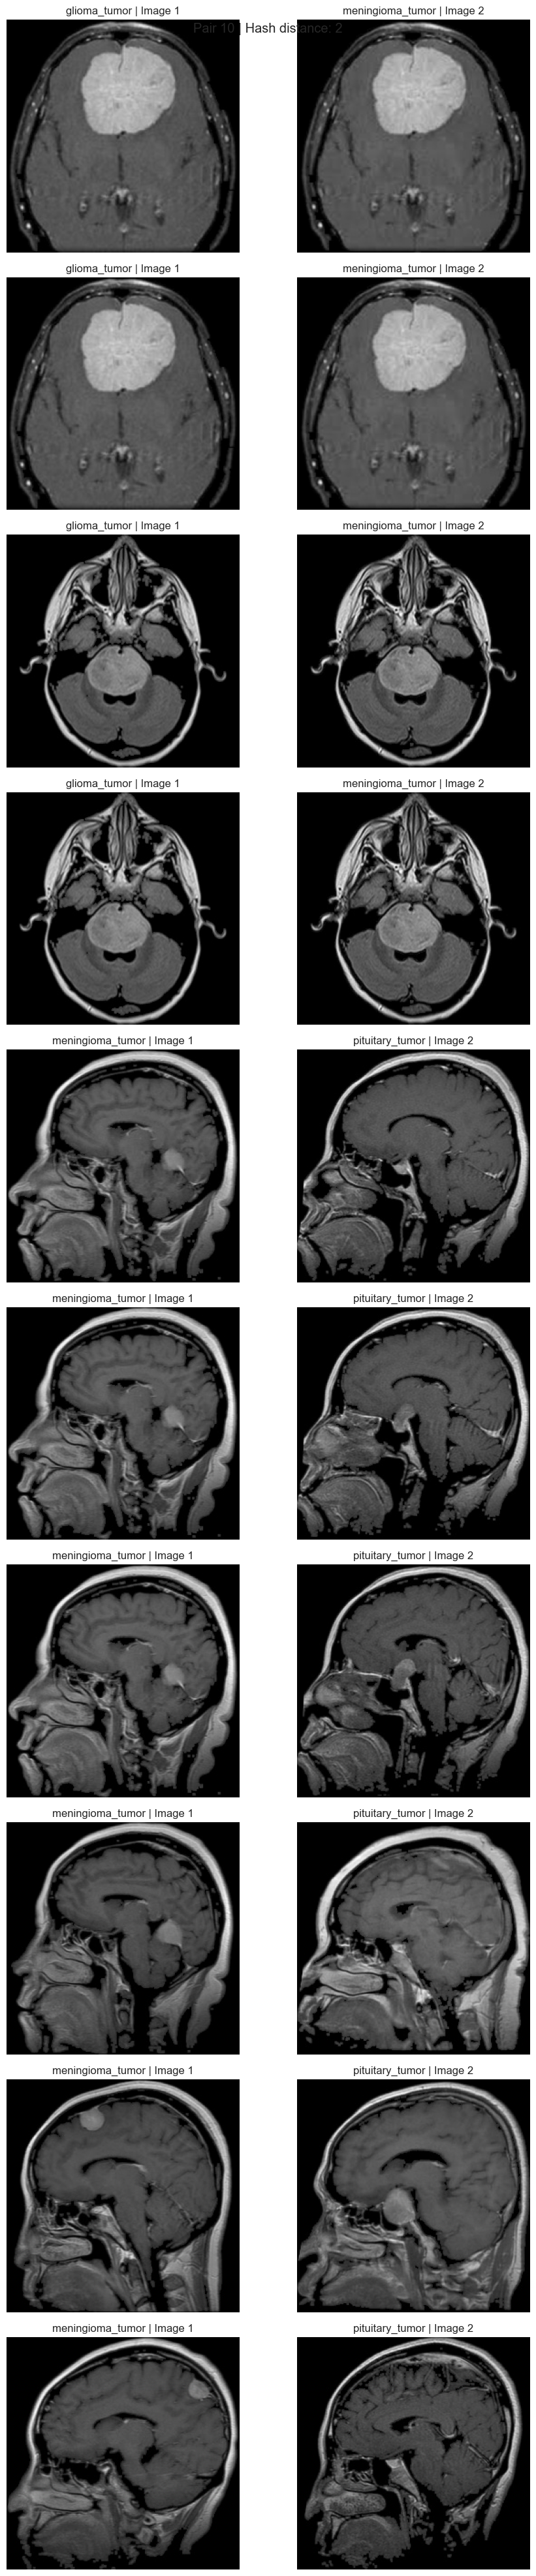

In [15]:
fig, axes = plt.subplots(
    len(cross_class_near), 2,
    figsize=(10, 4 * len(cross_class_near))
)

for i, (_, row) in enumerate(cross_class_near.iterrows()):

    img1 = Image.open(row["image_1"]).convert("RGB")
    img2 = Image.open(row["image_2"]).convert("RGB")

    axes[i, 0].imshow(img1)
    axes[i, 0].set_title(f'{row["class_1"]} | Image 1')
    axes[i, 0].axis("off")

    axes[i, 1].imshow(img2)
    axes[i, 1].set_title(f'{row["class_2"]} | Image 2')
    axes[i, 1].axis("off")

    fig.suptitle(
        f'Pair {i+1} | Hash distance: {row["hash_distance"]}'
    )

plt.tight_layout()
plt.show()

In [16]:
import shutil

QUARANTINE_DIR = PROCESSED_DIR / "exact_duplicates"

removed_count = 0

for image_hash, paths in duplicate_groups.items():

    # Keep the first image
    duplicates_to_move = paths[1:]

    for path in duplicates_to_move:
        source = Path(path)

        destination_dir = QUARANTINE_DIR / source.parent.name
        destination_dir.mkdir(parents=True, exist_ok=True)

        destination = destination_dir / source.name

        # Avoid overwriting files
        counter = 1
        while destination.exists():
            destination = destination_dir / f"{source.stem}_{counter}{source.suffix}"
            counter += 1

        shutil.move(str(source), str(destination))
        removed_count += 1

print("Duplicates moved:", removed_count)
print("Backup location:", QUARANTINE_DIR)

Duplicates moved: 251
Backup location: C:\cs\Projects\cv-projects\Brain_tumor\data\processed\exact_duplicates


In [17]:
image_records = []

for class_name in CLASS_NAMES:
    class_dir = DATASET_DIR / class_name

    for image_path in class_dir.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            image_records.append({
                "image_path": str(image_path),
                "filename": image_path.name,
                "class": class_name
            })

df = pd.DataFrame(image_records)

print("Remaining images:", len(df))
display(df["class"].value_counts())

Remaining images: 2845


class
glioma_tumor        885
pituitary_tumor     834
meningioma_tumor    816
normal              310
Name: count, dtype: int64

In [18]:
from collections import defaultdict
import hashlib

hash_groups = defaultdict(list)

for image_path in tqdm(df["image_path"]):
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        image_hash = hashlib.sha256(img.tobytes()).hexdigest()
        hash_groups[image_hash].append(image_path)

remaining_duplicates = {
    h: paths for h, paths in hash_groups.items()
    if len(paths) > 1
}

print("Remaining duplicate groups:", len(remaining_duplicates))
print(
    "Extra duplicate images:",
    sum(len(paths) - 1 for paths in remaining_duplicates.values())
)

  0%|          | 0/2845 [00:00<?, ?it/s]

Remaining duplicate groups: 0
Extra duplicate images: 0


In [19]:
from sklearn.model_selection import train_test_split

# 70% Training, 30% Temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["class"],
    random_state=42
)

# Split temporary data into 15% Validation and 15% Testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class"],
    random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total images:", len(df))

Training images: 1991
Validation images: 427
Testing images: 427
Total images: 2845


In [20]:
split_counts = pd.DataFrame({
    "Total": df["class"].value_counts(),
    "Train": train_df["class"].value_counts(),
    "Validation": val_df["class"].value_counts(),
    "Test": test_df["class"].value_counts()
}).reindex(CLASS_NAMES)

display(split_counts)

,Total,Train,Validation,Test
class,,,,
normal,310,217,47,46
glioma_tumor,885,619,133,133
meningioma_tumor,816,571,122,123
pituitary_tumor,834,584,125,125


In [21]:
split_percentages = pd.DataFrame({
    "Train": train_df["class"].value_counts(normalize=True) * 100,
    "Validation": val_df["class"].value_counts(normalize=True) * 100,
    "Test": test_df["class"].value_counts(normalize=True) * 100
}).reindex(CLASS_NAMES)

display(split_percentages.round(2))

,Train,Validation,Test
class,,,
normal,10.90,11.01,10.77
glioma_tumor,31.09,31.15,31.15
meningioma_tumor,28.68,28.57,28.81
pituitary_tumor,29.33,29.27,29.27


In [22]:
SPLIT_DIR = PROCESSED_DIR / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(SPLIT_DIR / "train.csv", index=False)
val_df.to_csv(SPLIT_DIR / "validation.csv", index=False)
test_df.to_csv(SPLIT_DIR / "test.csv", index=False)

print("Split manifests saved successfully!")

Split manifests saved successfully!
